In [1]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt 
from models.models import FrequencyAdaptationLayer, CNN, classifier
from dataloader.dataloader import data_generator
from sklearn.metrics import f1_score, accuracy_score
# from models.loss import SinkhornDistance
# from pytorch_metric_learning import losses
# from algorithms.RAINCOAT import RAINCOAT
from models.models import classifier
import umap


In [2]:
class Boiler_config():
    def __init__(self):
        super(Boiler_config, self).__init__()
        self.class_names = ['0','1']
        self.sequence_len = 6
        self.scenarios = [("1", "2"),("1", "3"),("2", "3")]
        # self.scenarios = [("1", "2")]
        self.num_classes = 2
        self.sequence_len = 36
        self.shuffle = True
        self.drop_last = False
        self.normalize = True

        # model configs
        self.input_channels = 20
        self.kernel_size = 5
        self.stride = 1
        self.dropout = 0.2

        # features
        self.mid_channels = 32
        self.final_out_channels = 32
        self.features_len = 1

        # TCN features
        self.tcn_layers = [32,64]
        self.tcn_final_out_channles = self.tcn_layers[-1]
        self.tcn_kernel_size = 15# 25
        self.tcn_dropout = 0.0

        # lstm features
        self.lstm_hid = 128
        self.lstm_n_layers = 1
        self.lstm_bid = False

        # discriminator
        self.DSKN_disc_hid = 128
        self.hidden_dim = 500
        self.disc_hid_dim = 100

        self.fourier_modes = 18
        self.AR_hid_dim = 32
        self.intra_only = True
        self.num_splits = 4
        self.AR_hid_dim_raw = self.input_channels



data_path = 'dataset/Boiler'
src_id = '1'
trg_id = '2'
dataset_configs = Boiler_config()
hparams = {"batch_size":64, 'learning_rate':1e-3,'weight_decay': 1e-4,'num_epochs': 100}

src_train_dl = data_generator(data_path, src_id,dataset_configs, hparams, "test")
trg_train_dl = data_generator(data_path, trg_id, dataset_configs,hparams, "test")

freq_adapter = FrequencyAdaptationLayer(
            seq_len=36,
            channels=20,
            amp_scale=0.76704,
            phase_scale=0.88275,
            hidden_dim=64
        )
feature_extractor = CNN(Boiler_config())
Classifier = classifier(Boiler_config())
network = nn.Sequential(freq_adapter, feature_extractor, Classifier)
network.load_state_dict(torch.load(f'exp/Boiler/proposed/{src_id}_to_{trg_id}_run_0/checkpoint.pt')['best'])

/tmp/ipykernel_175179/210388410.py:68: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  network.load_state_dict(torch.load(f'exp/Boiler/proposed/{src_id}_to_{trg_id}_run_0/chec

<All keys matched successfully>

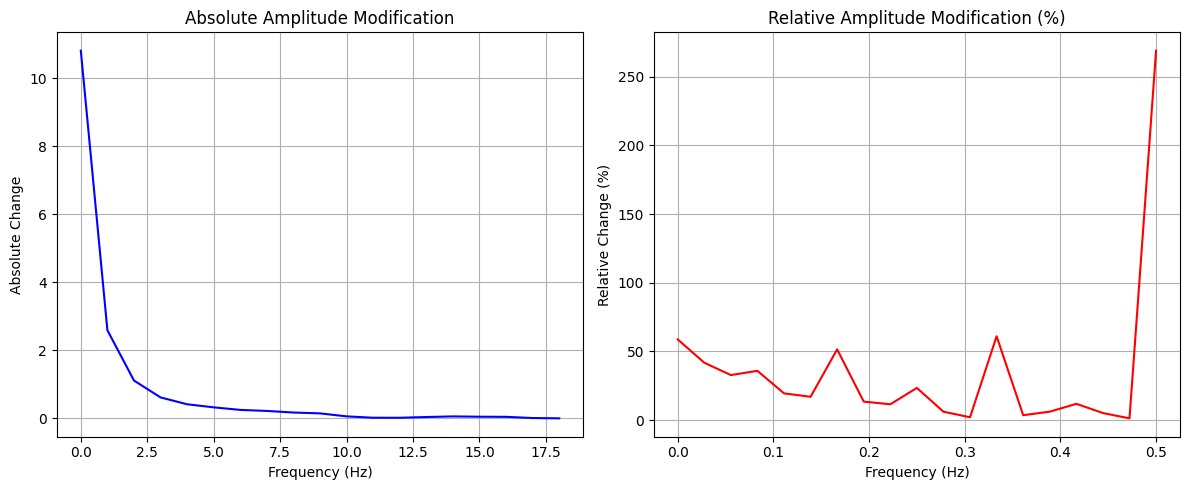

In [3]:
feat_original_list = []
feat_src_list = []
feat_adapted_list = []
labels_list = []
src_labels_list = []
absolute_amp_diff_list = []
relative_amp_diff_list = []
network.to(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
feature_extractor.eval()
freq_adapter.eval()
with torch.no_grad():
    for step, (trg_x, trg_y, _) in enumerate(trg_train_dl):
        trg_x = trg_x.float().to(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
        orig_feat, _ = feature_extractor(trg_x)
        adapted_x = freq_adapter(trg_x)
        adapted_feat, _ = feature_extractor(adapted_x)
        feat_original_list.append(orig_feat.cpu().numpy())
        feat_adapted_list.append(adapted_feat.cpu().numpy())
        labels_list.append(trg_y.cpu().numpy())
        # diff = torch.norm(adapted_feat - orig_feat)
        # print(f"Feature Shift Magnitude: {diff.item()}")
        orig_fft = torch.fft.rfft(trg_x, dim=-1)
        adapted_fft = torch.fft.rfft(adapted_x, dim=-1)
        
        # 提取振幅 (Amplitude)
        orig_amp = torch.abs(orig_fft)
        adapted_amp = torch.abs(adapted_fft)
        
        # 计算绝对变化量：|适应后振幅 - 原始振幅|
        abs_diff = torch.abs(adapted_amp - orig_amp)
        # 跨 Batch 和 Channel 取平均，得到每个频率 Bin 的平均变化量
        # 形状变化: [Batch, Channel, Freq_len] -> [Freq_len]
        mean_abs_diff = abs_diff.mean(dim=(0, 1))
        absolute_amp_diff_list.append(mean_abs_diff.cpu().numpy())
        
        # 计算相对变化率（百分比）：|变化量| / (原始振幅 + epsilon 防止除0)
        # 这能看出模型是不是放大了那些原本能量很小的频段（比如高频噪声）
        rel_diff = abs_diff / (orig_amp + 1e-8)
        mean_rel_diff = rel_diff.mean(dim=(0, 1))
        relative_amp_diff_list.append(mean_rel_diff.cpu().numpy())
    for step, (src_x, src_y, _) in enumerate(src_train_dl):
        src_x = src_x.float().to(torch.device('cuda' if torch.cuda.is_available() else 'cpu'))
        src_feat, _ = feature_extractor(src_x)
        feat_src_list.append(src_feat.cpu().numpy())
        src_labels_list.append(src_y.cpu().numpy())
X_orig = np.concatenate(feat_original_list, axis=0)
X_adap = np.concatenate(feat_adapted_list, axis=0)
X_src = np.concatenate(feat_src_list, axis=0)
Y = np.concatenate(labels_list, axis=0)
Y_src = np.concatenate(src_labels_list, axis=0)
final_abs_diff = np.mean(absolute_amp_diff_list, axis=0)
final_rel_diff = np.mean(relative_amp_diff_list, axis=0)

# 如果你知道采样率（例如 100Hz），可以把 X 轴换算成真实的赫兹 (Hz)
# 假设 seq_len 是你时间序列的长度，fs 是采样率
fs = 1  # 替换成你数据集的真实采样率
seq_len = trg_x.shape[-1]
freqs_hz = np.fft.rfftfreq(seq_len, d=1/fs)
# 这里为了通用，直接使用 Frequency Bin 的索引
freq_bins = np.arange(len(final_abs_diff))

# 画图
plt.figure(figsize=(12, 5))

# 图1：绝对振幅变化（看哪里被修改的能量最多）
plt.subplot(1, 2, 1)
plt.plot(freqs_hz, final_abs_diff, color='b')
plt.title("Absolute Amplitude Modification")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Absolute Change")
plt.grid(True)

# 图2：相对振幅变化（看哪里的修改幅度/比例最大）
plt.subplot(1, 2, 2)
plt.plot(freqs_hz, final_rel_diff * 100, color='r') # 乘以100转为百分比
plt.title("Relative Amplitude Modification (%)")
plt.xlabel("Frequency (Hz)")
plt.ylabel("Relative Change (%)")
plt.grid(True)

plt.tight_layout()
plt.show()

=== 定量评估指标 ===


Target 原始特征轮廓系数 (Silhouette Score): 0.2845
Target 适应后特征轮廓系数 (Silhouette Score): 0.1757
提升幅度: -0.1088

=== 定量指标：NMI (标准化互信息) ===
Target 原始特征 NMI 分数: 0.0017
Target 适应后特征 NMI 分数: 0.0052
NMI 提升幅度: +0.0035

=== 正在计算 UMAP 降维 (可能需要几十秒) ===


/mnt/cache/mengshichang/.conda/envs/SFDA/lib/python3.8/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/mnt/cache/mengshichang/.conda/envs/SFDA/lib/python3.8/site-packages/numba/np/ufunc/parallel.py:371: NumbaWarning: The TBB threading layer requires TBB version 2021 update 6 or later i.e., TBB_INTERFACE_VERSION >= 12060. Found TBB_INTERFACE_VERSION = 12050. The TBB threading layer is disabled.
  warnings.warn(problem)


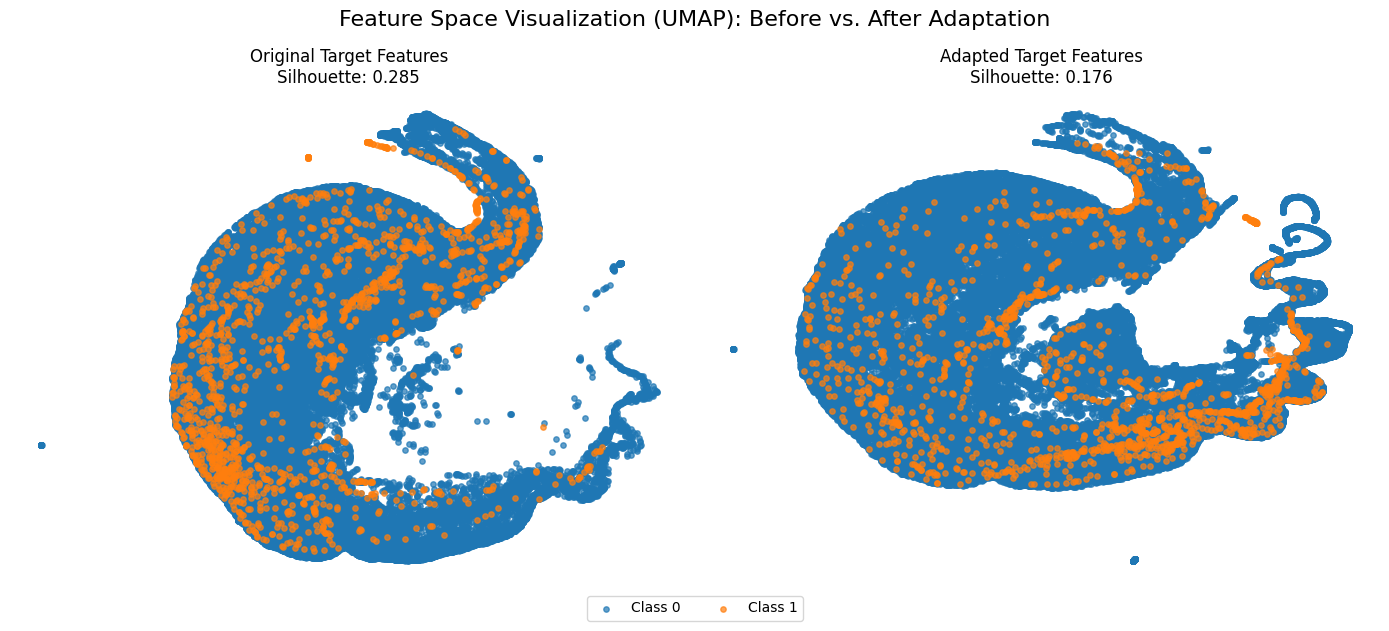

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import umap
from sklearn.metrics import silhouette_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import normalized_mutual_info_score
from sklearn.cluster import KMeans

# 假设你已经运行了你上面的代码，得到了 X_orig, X_adap, X_src, Y, Y_src
# X 形状应为 [N, Features] 且为 2D 数组。如果是 3D 的，记得用 X.reshape(X.shape[0], -1) 展平

# ==========================================
# 1. 定量分析：数值指标计算
# ==========================================
print("=== 定量评估指标 ===")

# 指标 A: Silhouette Score (在 Target 域上算，看类别是否分得更开)
sil_orig = silhouette_score(X_orig, Y)
sil_adap = silhouette_score(X_adap, Y)
print(f"Target 原始特征轮廓系数 (Silhouette Score): {sil_orig:.4f}")
print(f"Target 适应后特征轮廓系数 (Silhouette Score): {sil_adap:.4f}")
print(f"提升幅度: {sil_adap - sil_orig:+.4f}\n")

print("=== 定量指标：NMI (标准化互信息) ===")

# 1. 获取类别的真实数量 K
n_classes = len(np.unique(Y))

# 2. 对 Original Target Features 进行 K-Means 聚类
kmeans_orig = KMeans(n_clusters=n_classes, random_state=42, n_init=10)
cluster_labels_orig = kmeans_orig.fit_predict(X_orig) # 得到无监督聚类标签

# 3. 对 Adapted Target Features 进行 K-Means 聚类
kmeans_adap = KMeans(n_clusters=n_classes, random_state=42, n_init=10)
cluster_labels_adap = kmeans_adap.fit_predict(X_adap)

# 4. 计算 NMI
nmi_orig = normalized_mutual_info_score(Y, cluster_labels_orig)
nmi_adap = normalized_mutual_info_score(Y, cluster_labels_adap)

print(f"Target 原始特征 NMI 分数: {nmi_orig:.4f}")
print(f"Target 适应后特征 NMI 分数: {nmi_adap:.4f}")
print(f"NMI 提升幅度: {nmi_adap - nmi_orig:+.4f}\n")

# ==========================================
# 2. 定性分析：UMAP 降维可视化
# ==========================================
print("=== 正在计算 UMAP 降维 (可能需要几十秒) ===")
# 固定 random_state 以保证每次画图的结果一致
reducer = umap.UMAP(n_components=2, random_state=42)

# 将 original 和 adapted 拼在一起做降维，保证它们映射在同一个 2D 坐标系中方便对比
X_combined = np.concatenate([X_orig, X_adap], axis=0)
X_combined_2d = reducer.fit_transform(X_combined)

# 拆分回原来的两份
split_idx = X_orig.shape[0]
X_orig_2d = X_combined_2d[:split_idx]
X_adap_2d = X_combined_2d[split_idx:]

# 开始画图
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 获取类别的数量，用于分配颜色
classes = np.unique(Y)
cmap = plt.get_cmap('tab10') # 支持最多 10 个类别，类别更多请换 'tab20'

# 图1：Original Target Features
for cls in classes:
    idx = (Y == cls)
    axes[0].scatter(X_orig_2d[idx, 0], X_orig_2d[idx, 1], 
                    label=f'Class {cls}', alpha=0.7, s=15, c=[cmap(cls % 10)])
axes[0].set_title(f'Original Target Features\nSilhouette: {sil_orig:.3f}')
axes[0].axis('off') # 隐藏坐标轴，使得图看起来更干净

# 图2：Adapted Target Features
for cls in classes:
    idx = (Y == cls)
    axes[1].scatter(X_adap_2d[idx, 0], X_adap_2d[idx, 1], 
                    label=f'Class {cls}', alpha=0.7, s=15, c=[cmap(cls % 10)])
axes[1].set_title(f'Adapted Target Features\nSilhouette: {sil_adap:.3f}')
axes[1].axis('off')

# 添加图例
handles, labels = axes[1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(classes), bbox_to_anchor=(0.5, -0.05))

plt.suptitle("Feature Space Visualization (UMAP): Before vs. After Adaptation", fontsize=16)
plt.tight_layout()
plt.show()